# House Prices Prediction

## 1. Introduction

### Problem Statement

The goal of this project is to build a Machine Learning model
that predicts residential house prices based on various
property characteristics.

### Project Objective

Develop and evaluate regression models to predict house
sale prices accurately and understand the factors
that influence residential property values.

### Dataset

Ames Housing Dataset from the Kaggle
House Prices - Advanced Regression Techniques competition.

### Target Variable

- SalePrice

### Machine Learning Task

- Supervised Learning
- Regression

## 2. Data Understanding

### 2.1 Project Setup & Data Loading

#### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Load Dataset

In [2]:
base_path = "/kaggle/input/competitions/house-prices-advanced-regression-techniques"

train = pd.read_csv(f"{base_path}/train.csv")
test = pd.read_csv(f"{base_path}/test.csv")

#### Verify Dataset

In [3]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (1460, 81)
Test shape: (1459, 80)


### 2.2 Dataset Preview

In [4]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


#### 2.3 Dataset Structure

In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

#### 2.4 Missing Values Summary

In [6]:
missing_summary = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": (train.isnull().sum() / len(train)) * 100
})

missing_summary = missing_summary[missing_summary["Missing Count"] > 0]

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


#### 2.5 Statistical Summary

In [7]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


**Initial Observations:**

- The training dataset contains 1,460 observations.
- The average sale price is approximately 180,921 USD.
- The median sale price is 163,000 USD.
- Sale prices show a potential right-skewed distribution.
- Some numerical features contain zero values, which may represent the absence of certain house features.
- The numerical features have different scales and ranges.

#### 2.6 Feature Types Analysis

In [8]:
train.dtypes.value_counts()

object     43
int64      35
float64     3
Name: count, dtype: int64

In [9]:
numerical_features = train.select_dtypes(include=["int64", "float64"]).columns

categorical_features = train.select_dtypes(include=["object"]).columns

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 38
Categorical features: 43


In [10]:
print("Numerical Features:")
print(numerical_features.tolist())

print("\nCategorical Features:")
print(categorical_features.tolist())

Numerical Features:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Features:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'Firepl

**Initial Observations:**

- The dataset contains 38 numerical columns and 43 categorical columns based on Pandas data types.
- Some numerical columns represent categorical or ordinal information.
- The `Id` column is an identifier rather than a meaningful property feature.
- `SalePrice` is the target variable.
- Categorical features include both nominal and ordinal variables.

These classifications will be reviewed during data preprocessing.

#### 2.7 Unique Values Analysis

In [11]:
pd.set_option("display.max_rows", None)
train.nunique().sort_values()


Alley               2
Street              2
Utilities           2
CentralAir          2
MasVnrType          3
HalfBath            3
GarageFinish        3
LandSlope           3
BsmtHalfBath        3
PavedDrive          3
PoolQC              3
ExterQual           4
BsmtQual            4
LotShape            4
BsmtExposure        4
FullBath            4
KitchenQual         4
BsmtFullBath        4
Fireplaces          4
KitchenAbvGr        4
MiscFeature         4
Fence               4
BsmtCond            4
LandContour         4
BldgType            5
FireplaceQu         5
LotConfig           5
ExterCond           5
Electrical          5
GarageCars          5
GarageQual          5
HeatingQC           5
MSZoning            5
YrSold              5
GarageCond          5
BsmtFinType2        6
Heating             6
BsmtFinType1        6
RoofStyle           6
Foundation          6
GarageType          6
SaleCondition       6
Functional          7
PoolArea            8
BedroomAbvGr        8
Condition2

In [12]:
pd.reset_option("display.max_rows")

**Initial Observations:**

- Features have different numbers of unique values.
- Some numerical columns represent categorical or ordinal information.
- Features such as `MSSubClass`, `OverallQual`, and `OverallCond` require special attention during feature classification.
- `Id` contains 1,460 unique values and represents a unique identifier.
- `Neighborhood` contains 25 distinct categories.

## 3. Exploratory Data Analysis

#### 3.1 Target Variable Distribution

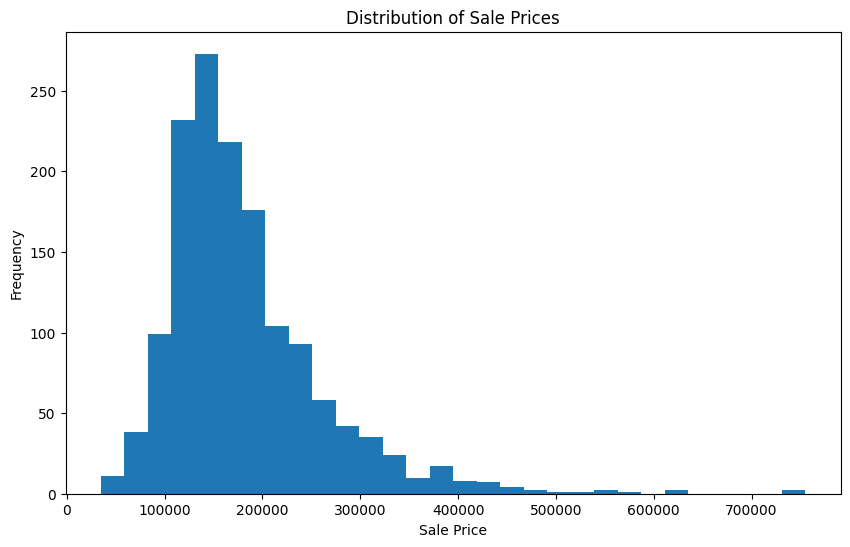

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(train["SalePrice"], bins=30)

plt.title("Distribution of Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

**Observations:**

- Most houses have sale prices between 100,000 USD and 200,000 USD.
- The target variable shows a right-skewed distribution.
- A small number of houses have significantly higher sale prices.
- Potential outliers may be present in the upper price range.
- The distribution is not symmetric.

#### 3.2 SalePrice Outlier Analysis

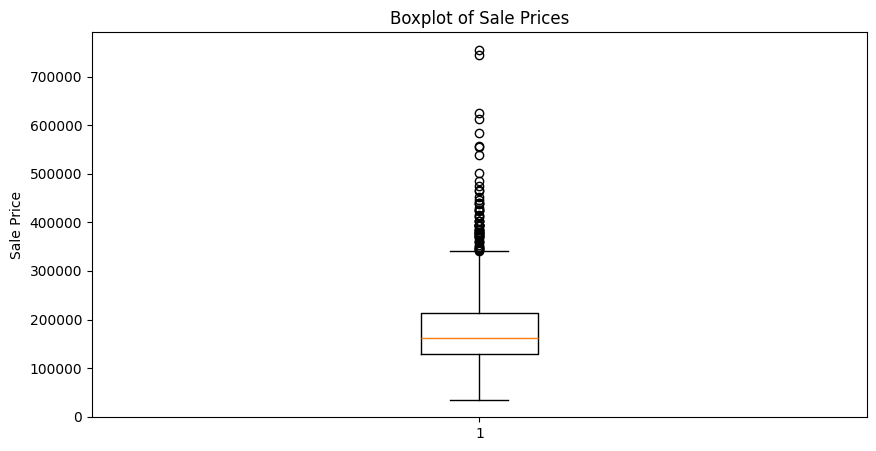

In [14]:
plt.figure(figsize=(10, 5))

plt.boxplot(train["SalePrice"])

plt.title("Boxplot of Sale Prices")
plt.ylabel("Sale Price")

plt.show()

**Observations:**

- The median sale price is approximately 163,000 USD.
- The middle 50% of sale prices are concentrated between approximately 130,000 USD and 214,000 USD.
- Several potential outliers appear above the upper whisker.
- Some houses have exceptionally high sale prices.
- These observations are not necessarily errors and should not be removed without further investigation.

In [15]:
Q1 = train["SalePrice"].quantile(0.25)
Q3 = train["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = train[
    (train["SalePrice"] < lower_bound) |
    (train["SalePrice"] > upper_bound)
]

print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of potential outliers:", len(outliers))

IQR: 84025.0
Lower Bound: 3937.5
Upper Bound: 340037.5
Number of potential outliers: 61


**Outlier Analysis:**

- The IQR is 84,025 USD.
- The upper bound is 340,037.5 USD.
- The lower bound is 3,937.5 USD.
- A total of 61 observations are identified as potential outliers.
- These observations represent approximately 4.18% of the training dataset.
- No observations fall below the lower bound.
- These observations will be retained for further investigation.

In [16]:
outliers.sort_values(
    by="SalePrice",
    ascending=False
)[["Id", "OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "SalePrice"]].head(10)

,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,SalePrice
691,692,10,4316,3,2444,755000
1182,1183,10,4476,3,2396,745000
1169,1170,10,3627,3,1930,625000
898,899,9,2364,3,2330,611657
803,804,9,2822,3,1734,582933
1046,1047,9,2868,3,1992,556581
440,441,10,2402,3,3094,555000
769,770,8,3279,3,1650,538000
178,179,9,2234,3,2216,501837
798,799,9,3140,3,1926,485000


**Further Investigation:**

- The 10 highest-priced potential outliers generally have high overall quality ratings.
- These houses also tend to have large living areas.
- All 10 houses have a garage capacity of 3 cars.
- Their high sale prices may be explained by their property characteristics.
- No observations will be removed at this stage.

#### 3.3 Relationship Between Living Area and Sale Price

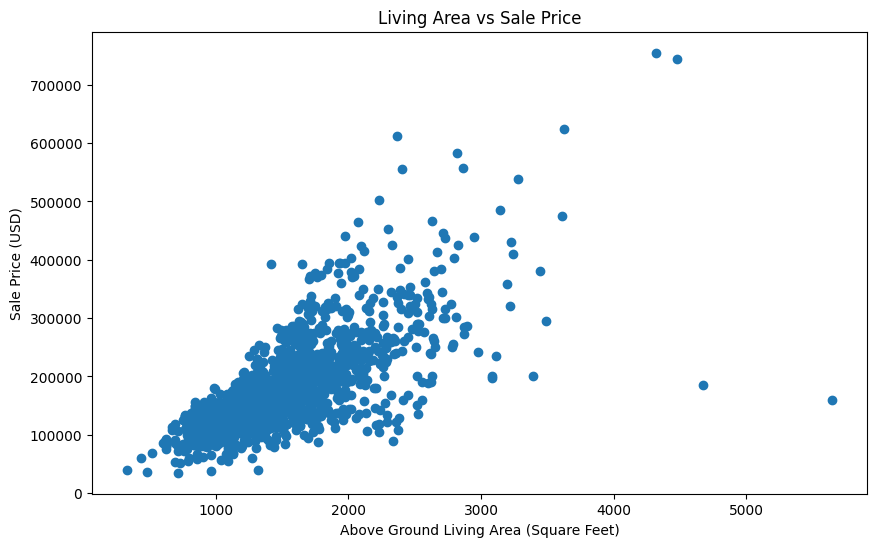

In [17]:
plt.figure(figsize=(10, 6))

plt.scatter(train["GrLivArea"], train["SalePrice"])

plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area (Square Feet)")
plt.ylabel("Sale Price (USD)")

plt.show()

**Observations:**

- A positive relationship appears to exist between living area and sale price.
- Larger houses generally tend to have higher sale prices.
- The relationship is not perfect, as houses with similar living areas can have different sale prices.
- Some unusual observations appear, including houses with very large living areas but relatively low sale prices.
- Living area is an important feature, but other property characteristics also influence sale prices.

In [18]:
correlation = train["GrLivArea"].corr(train["SalePrice"])

print("Correlation:", correlation)

Correlation: 0.7086244776126523


**Correlation Analysis:**

- The Pearson correlation coefficient between `GrLivArea` and `SalePrice` is approximately 0.709.
- This indicates a strong positive linear relationship.
- Houses with larger living areas generally tend to have higher sale prices.
- However, living area is not the only factor influencing house prices.
- Correlation does not imply causation.

#### 3.4 Relationship Between Overall Quality and Sale Price

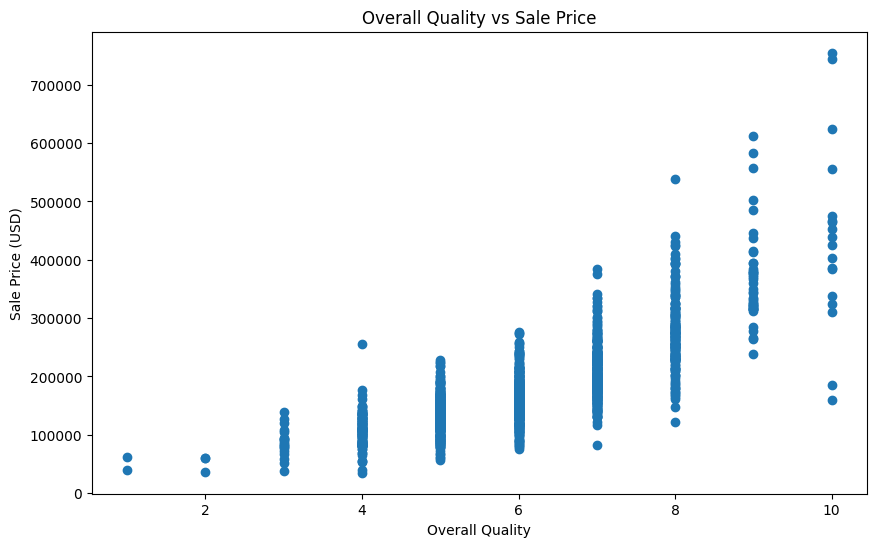

In [19]:
plt.figure(figsize=(10, 6))

plt.scatter(train["OverallQual"], train["SalePrice"])

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price (USD)")

plt.show()

**Observations:**

- A strong positive relationship appears to exist between overall quality and sale price.
- Houses with higher quality ratings generally tend to have higher sale prices.
- Houses with the same quality rating can still have significantly different sale prices.
- Overall quality is an important feature, but other property characteristics also influence sale prices.
- The vertical distribution of points is expected because `OverallQual` is an ordinal feature with integer values from 1 to 10.

In [20]:
correlation = train["OverallQual"].corr(
    train["SalePrice"],
    method="spearman"
)

print("Spearman Correlation:", correlation)

Spearman Correlation: 0.8098285862017292


**Correlation Analysis:**

- The Spearman correlation coefficient between `OverallQual` and `SalePrice` is approximately 0.810.
- This indicates a strong positive monotonic relationship.
- Higher overall quality ratings are generally associated with higher sale prices.
- Overall quality appears to be an important feature for predicting house prices.

#### 3.5 Correlation Analysis

In [21]:
numerical_corr = train.select_dtypes(
    include=["int64", "float64"]
).corr()

numerical_corr["SalePrice"].sort_values(ascending=False)

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

**Observations:**

- `OverallQual` has the strongest positive correlation with `SalePrice` (0.791).
- `GrLivArea` also shows a strong positive correlation (0.709).
- Features such as `GarageCars`, `GarageArea`, and `TotalBsmtSF` show moderate to strong positive correlations with the target.
- Several features have weak linear correlations with `SalePrice`.
- The `Id` column is an identifier and does not represent a meaningful property characteristic.
- Correlation does not imply causation, and weak linear correlation does not necessarily mean a feature is useless for prediction.

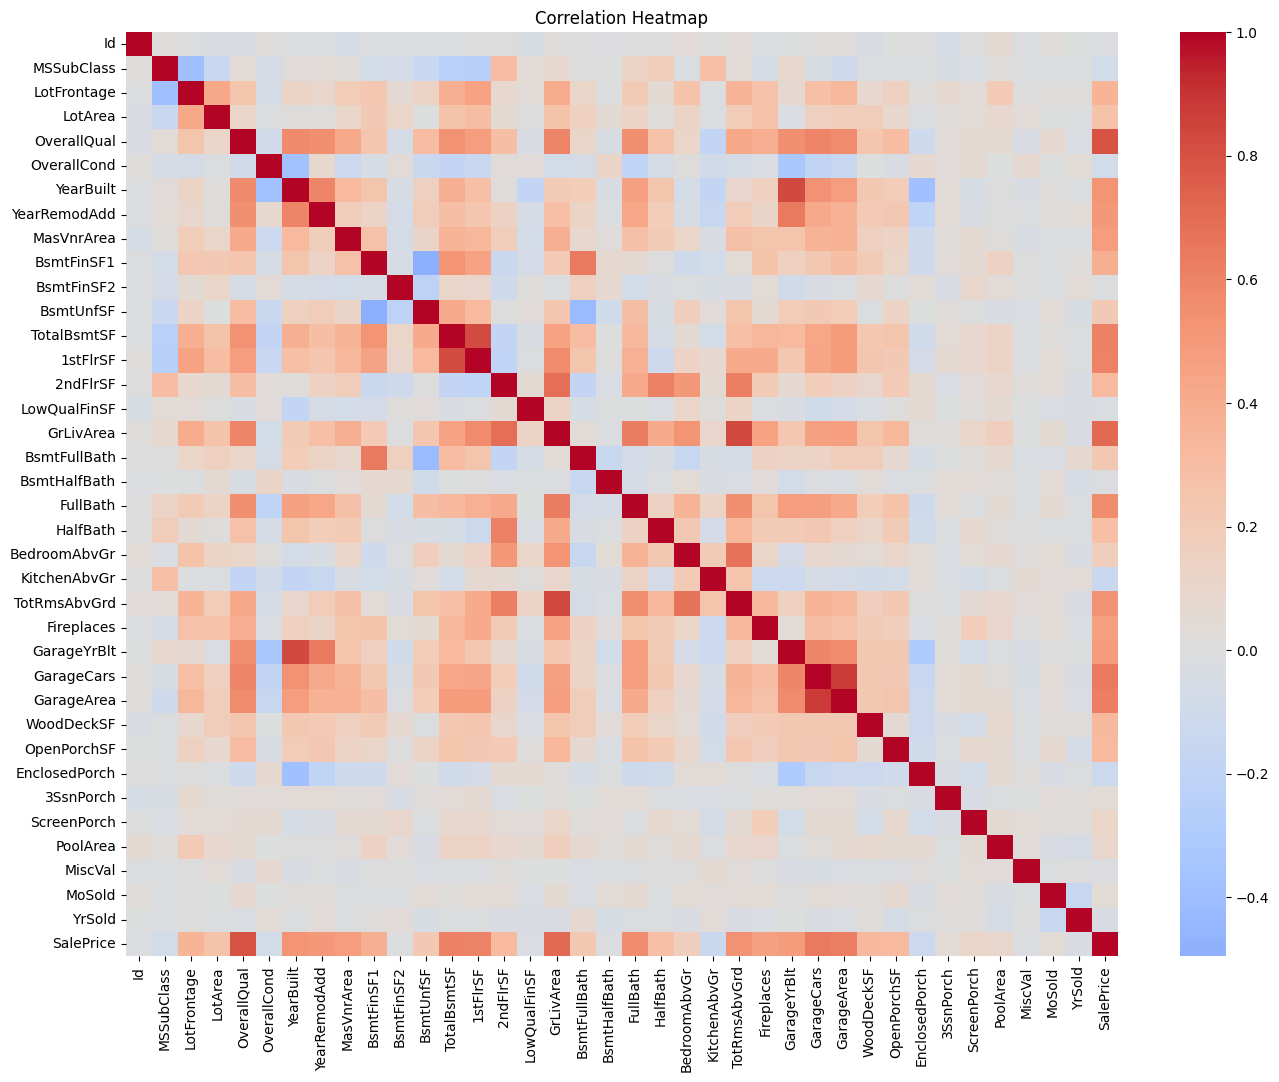

In [22]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    numerical_corr,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

**Observations:**

- `OverallQual` and `GrLivArea` show strong positive correlations with `SalePrice`.
- Several features are strongly correlated with each other.
- `GarageCars` and `GarageArea` show a strong positive correlation.
- `TotalBsmtSF` and `1stFlrSF` also show a strong positive correlation.
- `GrLivArea` and `TotRmsAbvGrd` exhibit a strong positive relationship.
- These strong correlations may indicate potential multicollinearity between some numerical features.
- Multicollinearity will be considered during model development and evaluation.

#### 3.6 Categorical Features Analysis

This section explores the distribution of categorical features to understand the most frequent categories and their representation in the dataset.

In [23]:
categorical_features = train.select_dtypes(include=["object"]).columns

for col in categorical_features:
    print(f"{col}: {train[col].nunique()} unique categories")

MSZoning: 5 unique categories
Street: 2 unique categories
Alley: 2 unique categories
LotShape: 4 unique categories
LandContour: 4 unique categories
Utilities: 2 unique categories
LotConfig: 5 unique categories
LandSlope: 3 unique categories
Neighborhood: 25 unique categories
Condition1: 9 unique categories
Condition2: 8 unique categories
BldgType: 5 unique categories
HouseStyle: 8 unique categories
RoofStyle: 6 unique categories
RoofMatl: 8 unique categories
Exterior1st: 15 unique categories
Exterior2nd: 16 unique categories
MasVnrType: 3 unique categories
ExterQual: 4 unique categories
ExterCond: 5 unique categories
Foundation: 6 unique categories
BsmtQual: 4 unique categories
BsmtCond: 4 unique categories
BsmtExposure: 4 unique categories
BsmtFinType1: 6 unique categories
BsmtFinType2: 6 unique categories
Heating: 6 unique categories
HeatingQC: 5 unique categories
CentralAir: 2 unique categories
Electrical: 5 unique categories
KitchenQual: 4 unique categories
Functional: 7 unique cat

**Observations:**

- The dataset contains 43 categorical features.
- Most categorical features have a relatively small number of unique categories.
- `Neighborhood` has the highest number of unique categories (25).
- Some features, such as `Street` and `CentralAir`, contain only two categories.
- Categorical features will require appropriate encoding during data preprocessing.

##### Neighborhood Distribution

The `Neighborhood` feature represents the physical location of each house within the city.

This analysis examines the number of houses in each neighborhood to understand how observations are distributed across different locations.

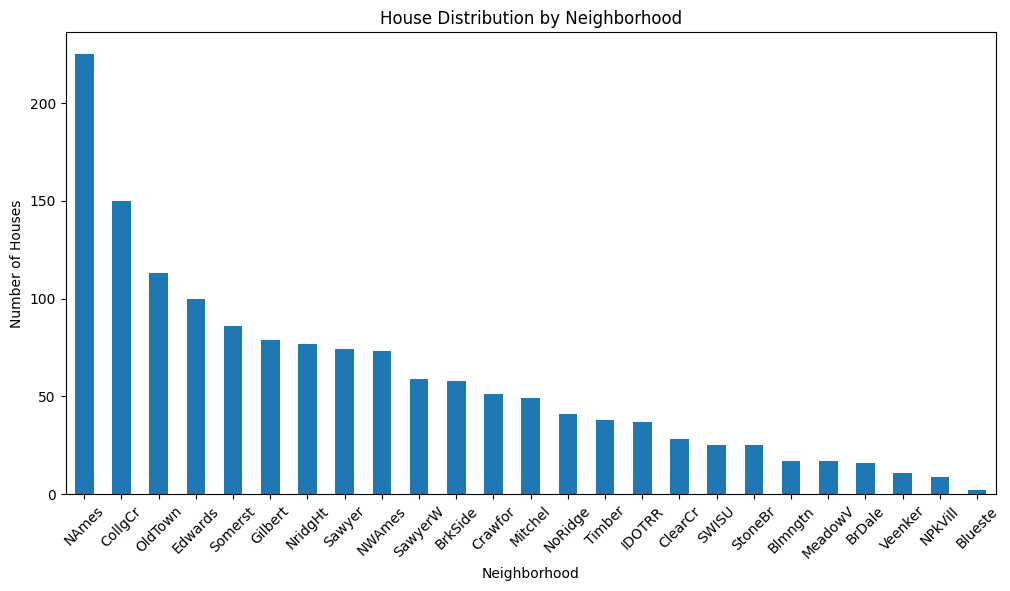

In [24]:
plt.figure(figsize=(12, 6))

train["Neighborhood"].value_counts().plot(kind="bar")

plt.title("House Distribution by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Houses")

plt.xticks(rotation=45)
plt.show()

**Observations:**

- `NAmes` has the highest number of houses in the training dataset.
- `CollgCr`, `OldTown`, and `Edwards` are also among the most represented neighborhoods.
- `Blueste` has the lowest number of houses.
- The distribution of houses across neighborhoods is uneven.
- `Neighborhood` may provide useful information for predicting house prices.

## 4. Data Preprocessing

## Project Progress

The following phases have been completed:

- [x] Phase 1: Introduction & Business Understanding
- [x] Phase 2: Data Understanding
- [x] Phase 3: Exploratory Data Analysis (EDA)

### Next Steps

- [ ] Phase 4: Data Preprocessing
- [ ] Phase 5: Model Training
- [ ] Phase 6: Model Evaluation
- [ ] Phase 7: Hyperparameter Tuning
- [ ] Phase 8: Final Model & Kaggle Submission
- [ ] Phase 9: GitHub Documentation

**Current Status:** Completed the initial data exploration. The next step is to prepare the dataset for Machine Learning models.